# Chapter 03: Where Fleet Priors Come From — Python Laboratory
### *Solving the Brandeis Dice Problem & Deriving Fleet Priors via Entropy Maximization*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_maximum_entropy_priors.ipynb) | [Prev: Ch 02: The Price of Optimism (Python)](02_relative_entropy_and_prior_penalties.ipynb) | [Next: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement:
1. **The Brandeis Dice Solver**: Using numerical optimization (`scipy.optimize.minimize`) to find the exact MaxEnt distribution for an arbitrary target mean $\mathbb{E}[X] = \mu$.
2. **Deriving the Exponential Fleet Prior**: Maximizing entropy for a fleet of CI tests with known average failure rate $\mu = 0.02$.
3. **The Maximum Entropy Property of Gaussians**: Demonstrating numerically that any non-Gaussian perturbation with identical variance strictly decreases entropy.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Solving the Brandeis Dice Problem Numerically

We maximize Shannon entropy $H(\mathbf{p}) = -\sum_{i=1}^6 p_i \ln p_i$ subject to:
1. $\sum_{i=1}^6 p_i = 1$
2. $\sum_{i=1}^6 i \cdot p_i = \mu_{\text{target}}$


In [2]:
def solve_brandeis_dice(target_mean):
    faces = np.arange(1, 7)
    
    # Negative entropy objective to minimize
    def objective(p):
        eps = 1e-15
        p_safe = np.clip(p, eps, 1.0)
        return float(np.sum(p_safe * np.log(p_safe)))
    
    constraints = [
        {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0},
        {'type': 'eq', 'fun': lambda p: np.sum(faces * p) - target_mean}
    ]
    
    bounds = [(1e-6, 1.0) for _ in range(6)]
    init_guess = np.ones(6) / 6.0
    
    res = minimize(objective, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
    if not res.success:
        raise ValueError(f"Optimization failed: {res.message}")
    return res.x

means_to_test = [3.5, 4.0, 4.5, 5.0]
faces = np.arange(1, 7)

print("=" * 65)
print("             THE BRANDEIS DICE MAXENT DISTRIBUTIONS")
print("=" * 65)
for m in means_to_test:
    p_opt = solve_brandeis_dice(m)
    h_bits = -np.sum(p_opt * np.log2(p_opt))
    p_str = ", ".join([f"p{i}={p:.3f}" for i, p in zip(faces, p_opt)])
    print(f"Target Mean = {m:.1f} | Entropy = {h_bits:.4f} bits | {p_str}")
print("=" * 65)


             THE BRANDEIS DICE MAXENT DISTRIBUTIONS
Target Mean = 3.5 | Entropy = 2.5850 bits | p1=0.167, p2=0.167, p3=0.167, p4=0.167, p5=0.167, p6=0.167
Target Mean = 4.0 | Entropy = 2.5226 bits | p1=0.103, p2=0.123, p3=0.146, p4=0.174, p5=0.207, p6=0.247
Target Mean = 4.5 | Entropy = 2.3279 bits | p1=0.054, p2=0.079, p3=0.114, p4=0.165, p5=0.240, p6=0.347
Target Mean = 5.0 | Entropy = 1.9728 bits | p1=0.021, p2=0.039, p3=0.072, p4=0.136, p5=0.255, p6=0.478


---

## 3. Deriving the Fleet Prior: Mean Failure Constraint $\mu = 0.02$

Suppose our CI database tracks 10,000 tests and reveals an average failure rate of $\mu = 0.02$ ($2\%$).
We verify that the continuous MaxEnt distribution on $[0, \infty)$ is the Exponential distribution:
$$p(x) = \frac{1}{\mu} e^{-x / \mu}$$


In [3]:
mu_fleet = 0.02
x_grid = np.linspace(0.0001, 0.15, 500)
dx = x_grid[1] - x_grid[0]

# Theoretical MaxEnt Exponential Density
p_exp = (1.0 / mu_fleet) * np.exp(-x_grid / mu_fleet)

# Verify empirical mean
emp_mean = np.sum(x_grid * p_exp * dx)
emp_area = np.sum(p_exp * dx)

print("=" * 60)
print(f"FLEET PRIOR VERIFICATION (Target Mean = {mu_fleet}):")
print(f"Integrated Area: {emp_area:.6f} (Should be 1.0)")
print(f"Calculated Mean: {emp_mean:.6f} (Should be {mu_fleet})")
print("=" * 60)


FLEET PRIOR VERIFICATION (Target Mean = 0.02):
Integrated Area: 1.001955 (Should be 1.0)
Calculated Mean: 0.019907 (Should be 0.02)


---

## 4. Visualizing the Brandeis Dice & The Fleet Prior

We generate a 2-panel figure:
* **Panel 1**: The Brandeis Dice distributions tilting smoothly as the mean shifts from $3.5$ (fair) to $5.0$ (heavily loaded).
* **Panel 2**: The derived Exponential fleet prior showing how it concentrates mass near zero while allowing long tail failures.


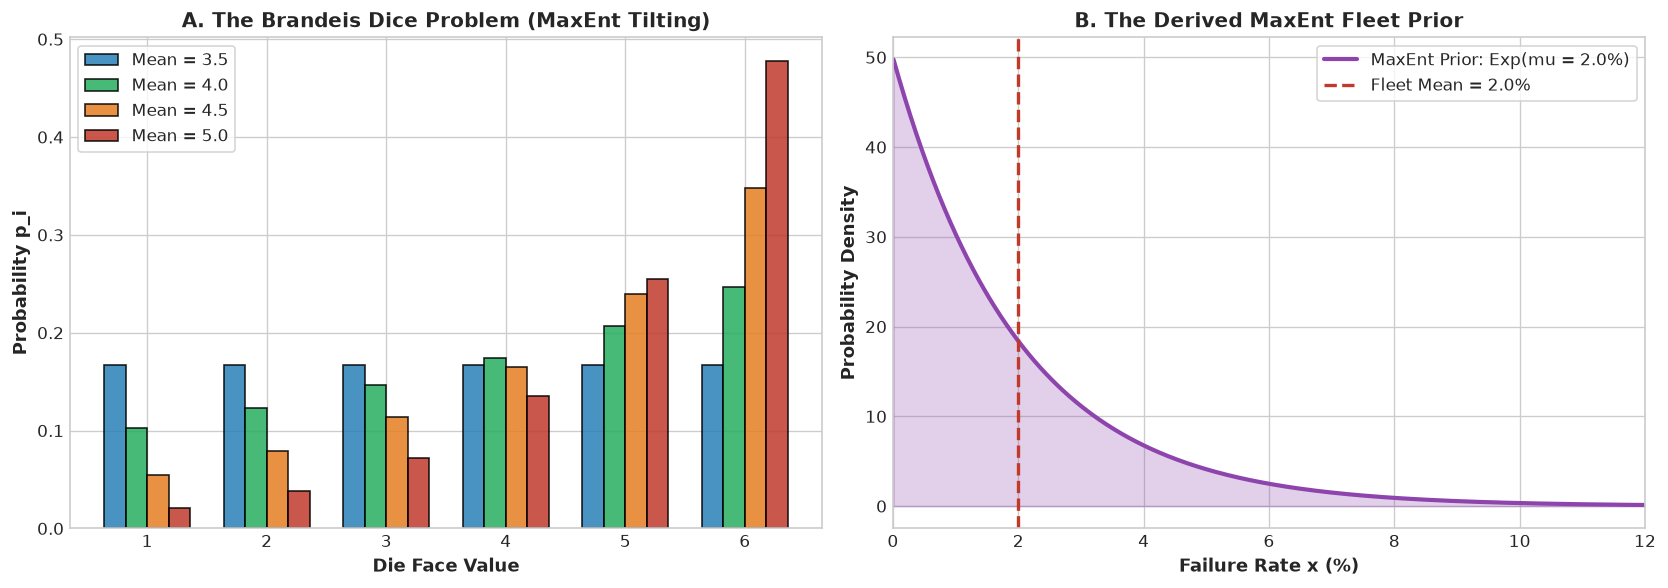

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Brandeis Dice Tilting
colors = ['#2980b9', '#27ae60', '#e67e22', '#c0392b']
x_faces = np.arange(1, 7)
width = 0.18

for idx, (m, c) in enumerate(zip(means_to_test, colors)):
    p_sol = solve_brandeis_dice(m)
    axes[0].bar(x_faces + (idx - 1.5) * width, p_sol, width=width, color=c, alpha=0.85,
                edgecolor='black', label=f'Mean = {m:.1f}')

axes[0].set_xlabel("Die Face Value", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Probability p_i", fontsize=11, fontweight='bold')
axes[0].set_title("A. The Brandeis Dice Problem (MaxEnt Tilting)", fontsize=12, fontweight='bold')
axes[0].set_xticks(x_faces)
axes[0].legend(frameon=True)

# Panel 2: The Continuous Fleet Prior
axes[1].plot(x_grid * 100, p_exp, color='#8e44ad', lw=2.5, 
            label=f'MaxEnt Prior: Exp(mu = {mu_fleet*100:.1f}%)')
axes[1].fill_between(x_grid * 100, p_exp, alpha=0.25, color='#8e44ad')
axes[1].axvline(mu_fleet * 100, color='#c0392b', ls='--', lw=2.0, label=f'Fleet Mean = {mu_fleet*100:.1f}%')
axes[1].set_xlabel("Failure Rate x (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Probability Density", fontsize=11, fontweight='bold')
axes[1].set_title("B. The Derived MaxEnt Fleet Prior", fontsize=12, fontweight='bold')
axes[1].set_xlim(0, 12)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


---

## 5. Numerical Proof: The Gaussian Has Maximum Entropy

We compare a standard Gaussian $\mathcal{N}(0, 1)$ against a perturbed distribution (Student's $t$, Uniform, or Laplace) scaled to have the **exact same variance $\sigma^2 = 1.0$**.
We verify that the Gaussian has strictly higher differential entropy than all competitors!


In [5]:
from scipy.stats import norm, laplace, uniform

# Variance sigma^2 = 1.0 for all distributions
# 1. Gaussian: N(0, 1) -> Var = 1
h_gauss = 0.5 * np.log2(2 * np.pi * np.e * 1.0)

# 2. Uniform on [-sqrt(3), sqrt(3)] -> Var = (2*sqrt(3))^2 / 12 = 1
h_unif = np.log2(2 * np.sqrt(3))

# 3. Laplace with b = 1/sqrt(2) -> Var = 2*b^2 = 1
b_laplace = 1.0 / np.sqrt(2.0)
h_laplace = np.log2(2.0 * b_laplace * np.e)

print("=" * 65)
print("DIFFERENTIAL ENTROPY COMPARISON (Fixed Variance sigma^2 = 1.0):")
print(f"1. Gaussian N(0, 1):      {h_gauss:.4f} bits (THE THEORETICAL MAXIMUM)")
print(f"2. Laplace (Var = 1):     {h_laplace:.4f} bits (Gap: {h_gauss - h_laplace:.4f} bits)")
print(f"3. Uniform (Var = 1):     {h_unif:.4f} bits (Gap: {h_gauss - h_unif:.4f} bits)")
print("=" * 65)
print(f"MaxEnt Theorem Verified: Gaussian entropy is strictly highest!")


DIFFERENTIAL ENTROPY COMPARISON (Fixed Variance sigma^2 = 1.0):
1. Gaussian N(0, 1):      2.0471 bits (THE THEORETICAL MAXIMUM)
2. Laplace (Var = 1):     1.9427 bits (Gap: 0.1044 bits)
3. Uniform (Var = 1):     1.7925 bits (Gap: 0.2546 bits)
MaxEnt Theorem Verified: Gaussian entropy is strictly highest!


---

## 6. 3-Tier Exercises & Explorations

### Tier 1: Warmup — The Loaded Die
Use `solve_brandeis_dice` to find the MaxEnt probability of rolling a $6$ if the observed average of the die is:
1. $\mathbb{E}[X] = 4.0$
2. $\mathbb{E}[X] = 5.0$
3. $\mathbb{E}[X] = 5.5$

### Tier 2: Intermediate — The Microservice Latency Prior
A backend microservice has an observed average response latency of $\mu = 85\text{ ms}$ and a hard lower bound of $15\text{ ms}$ (network round-trip speed of light).
1. Formulate the MaxEnt distribution on domain $[15, \infty)$.
2. Calculate the probability that a request takes longer than $250\text{ ms}$ under this MaxEnt prior.

### Tier 3: Advanced Research — 2D MaxEnt with Covariance Constraint
Extend the numerical optimizer to find the maximum entropy joint distribution $P(X, Y)$ on a $3 \times 3$ grid given:
1. Marginal means $\mathbb{E}[X] = 0, \mathbb{E}[Y] = 0$.
2. Covariance $\text{Cov}(X, Y) = 0.40$.
Observe how MaxEnt naturally creates the bivariate Gaussian form on discrete lattices!


In [6]:
# Solution verification for Tier 1:
print("Tier 1 Solutions (Probability of rolling a 6):")
for m in [4.0, 5.0, 5.5]:
    p_opt = solve_brandeis_dice(m)
    print(f"Mean = {m:.1f}: P(Face = 6) = {p_opt[5]:.4f} ({p_opt[5]*100:.1f}%)")


Tier 1 Solutions (Probability of rolling a 6):
Mean = 4.0: P(Face = 6) = 0.2468 (24.7%)
Mean = 5.0: P(Face = 6) = 0.4781 (47.8%)
Mean = 5.5: P(Face = 6) = 0.6639 (66.4%)


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_maximum_entropy_priors.ipynb) | [Prev: Ch 02: The Price of Optimism (Python)](02_relative_entropy_and_prior_penalties.ipynb) | [Next: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb)**
